# Initial Screening — Breast Cancer Wisconsin (Diagnostic)

**Course:** UE 5BM753 — Supervised and Unsupervised Learning for Biology
**Part of:** the Breast Cancer Wisconsin (Diagnostic) final report, split into
per-step notebooks. See `00_Final_Report_.ipynb` for the combined narrative and
`README.md` for the overall conclusion.

**Question addressed here:** which standard classifier and clustering method work best as a baseline?

Compares many standard supervised and unsupervised methods side by side, to pick which one of each deserves a closer look later.

## Setup

Defines the paths used below, imports the reusable functions kept in
`01_scripts/`, and loads the data.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sys.path.append(os.path.join("..", "01_scripts"))
from dataset import load_data, get_feature_columns
from plots import plot_pca_projection

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110

DATA_PATH = os.path.join("..", "02_data", "raw", "10_Breast_Cancer_Wisconsin_Diagnostic.csv")
RESULTS_DIR = os.path.join("..", "04_results")
FIGURES_DIR = os.path.join("..", "05_figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

df = load_data(DATA_PATH)
features = get_feature_columns(df)

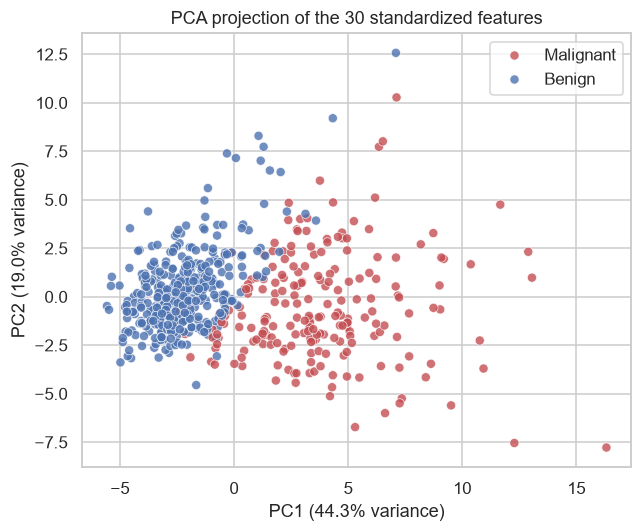

In [2]:
# Same scaling as the exploratory analysis: fit on all 569 samples. Reused below
# for clustering, and its PCA projection is reused only to visualize the clusters.
X_scaled_full = StandardScaler().fit_transform(df[features].values)
pca_full, X_pca_full = plot_pca_projection(
    X_scaled_full, df["label"].values,
    os.path.join(FIGURES_DIR, "02_pca_projection.png"), random_state=RANDOM_STATE,
)

## Initial Screening

Before going deeper into any one method, we first compare many standard methods side by side. This screening step helps us pick which one or two methods deserve a closer look later. Two families of methods are considered: supervised classifiers, and unsupervised clustering, covered in the two subsections below.

Model details are in `01_scripts/supervised_models.py` and `01_scripts/unsupervised_models.py`. The code below reruns the screening directly, so the results are reproducible from this notebook alone.

### Supervised classifiers

10 classifiers (Logistic Regression, KNN, 3 SVM kernels, LDA, QDA, Decision Tree,
Random Forest, AdaBoost) are compared to see how well each one predicts the diagnosis.
Each is scored on 6 metrics, each answering a different question:
- **Accuracy**: overall, how often is the prediction correct? Misleading here, since
  always predicting "benign" would already score fairly high.
- **Precision**: of all cases flagged malignant, how many really are? Low precision
  means unnecessary alarms and follow-up exams.
- **Recall**: of all actually malignant cases, how many are caught? Low recall means
  missed cancers, the costliest error clinically.
- **F1**: balances precision and recall equally into one score.
- **F2**: like F1, but weighs recall twice as much, matching the clinical priority of
  not missing a cancer.
- **ROC-AUC**: how well the model ranks malignant cases above benign ones, across
  every possible decision threshold, not just one.

These metrics are computed with 10-fold cross-validation: each model is trained and
tested multiple times on different splits of the data, giving a more reliable estimate
of performance than a single split. All models are trained on the same standardized
features, for one consistent pipeline. This has no effect on the tree-based models
(Decision Tree, Random Forest, AdaBoost): they split on per-feature thresholds, so
standardizing does not change their splits or predictions.

A held-out train/test split is also prepared here for reuse in later steps of the
analysis.

D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.

Train set: 398 samples, test set: 171 samples

Supervised screening (10-fold CV on train set, all 10 classifiers):


,model,accuracy_mean,recall_mean,f1_mean,f2_mean,roc_auc_mean
9,AdaBoost,0.9674,0.9324,0.9543,0.9406,0.9943
4,SVM (poly),0.8946,0.7167,0.8284,0.7567,0.9930
3,SVM (RBF),0.9749,0.9529,0.9655,0.9577,0.9927
0,Logistic Regression,0.9773,0.9524,0.9684,0.9586,0.9926
7,LDA,0.9523,0.8786,0.9297,0.8979,0.9922
2,SVM (linear),0.9598,0.9257,0.9434,0.9323,0.9918
8,QDA,0.9697,0.9386,0.9573,0.9457,0.9885
6,Random Forest,0.9473,0.9257,0.9286,0.9262,0.9845
1,K-Nearest Neighbors,0.9573,0.8986,0.9387,0.9140,0.9841
5,Decision Tree,0.9146,0.8981,0.8850,0.8918,0.9110



Top 3 supervised models by average rank across all 6 metrics:


,model,accuracy_mean,precision_mean,recall_mean,f1_mean,f2_mean,roc_auc_mean,avg_rank_across_6_metrics
0,Logistic Regression,0.977308,0.986607,0.952381,0.968440,0.958569,0.992610,2.00
1,SVM (RBF),0.974872,0.980000,0.952857,0.965475,0.957691,0.992667,2.67
2,AdaBoost,0.967372,0.980833,0.932381,0.954261,0.940643,0.994305,3.67


D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.

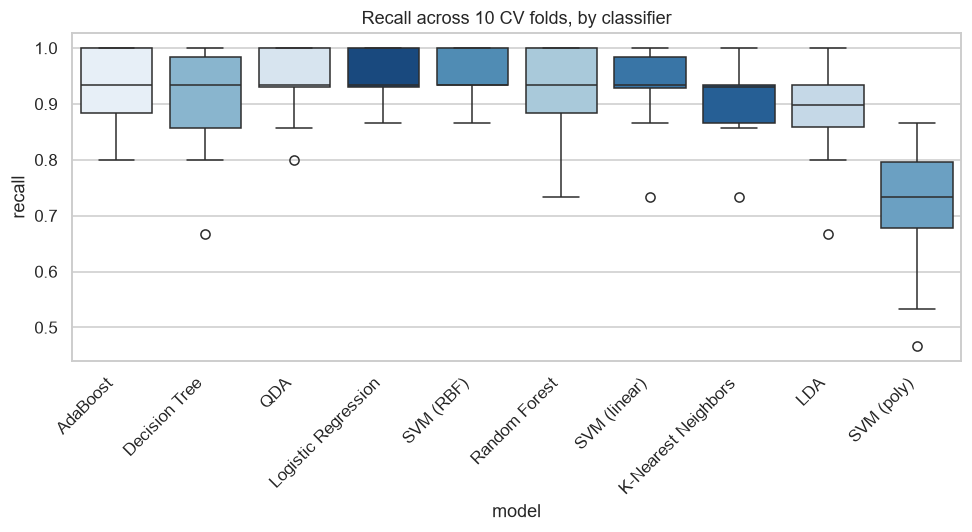

In [3]:
from preprocessing import split_and_scale
from supervised_models import get_baseline_classifiers
from evaluation import cross_validate_classifiers, cross_validate_classifiers_folds
from plots import plot_cv_score_boxplot

# "_all": split done on all 30 features.
# 70/30 split, not 80/20: malignant is the minority class (~37%), so a smaller
# test set would leave too few malignant cases to estimate recall reliably.
X_train_all, X_test_all, y_train, y_test, scaler_all = split_and_scale(
    df, features, test_size=0.3, random_state=RANDOM_STATE
)

classifiers = get_baseline_classifiers(random_state=RANDOM_STATE)
supervised_cv = cross_validate_classifiers(
    classifiers, X_train_all, y_train, cv_folds=10, random_state=RANDOM_STATE
)
supervised_cv.round(4).to_csv(os.path.join(RESULTS_DIR, "03_supervised_cv_results.csv"), index=False)

print(f"Train set: {X_train_all.shape[0]} samples, test set: {X_test_all.shape[0]} samples\n")
print("Supervised screening (10-fold CV on train set, all 10 classifiers):")
display(supervised_cv[["model", "accuracy_mean", "recall_mean", "f1_mean", "f2_mean", "roc_auc_mean"]].round(4))

# Condensed: lowest average rank across all 6 metrics -- no single metric
# decides a "best" model alone.
_metrics = ["accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "f2_mean", "roc_auc_mean"]
_avg_rank = supervised_cv.set_index("model")[_metrics].rank(ascending=False).mean(axis=1)
supervised_condensed = (
    supervised_cv.set_index("model")[_metrics]
    .assign(avg_rank_across_6_metrics=_avg_rank.round(2))
    .sort_values("avg_rank_across_6_metrics")
    .head(3)
    .reset_index()
)
supervised_condensed.to_csv(os.path.join(RESULTS_DIR, "03_screening_supervised_condensed.csv"), index=False)

print("\nTop 3 supervised models by average rank across all 6 metrics:")
display(supervised_condensed)

# Boxplot (for slides): recall across the 10 CV folds, one box per model --
# shows spread, not just the mean already in the table above.
recall_folds = cross_validate_classifiers_folds(
    classifiers, X_train_all, y_train, metric="recall", cv_folds=10, random_state=RANDOM_STATE
)
plot_cv_score_boxplot(
    recall_folds, "recall", os.path.join(FIGURES_DIR, "03_supervised_recall_boxplot.png"),
    title="Recall across 10 CV folds, by classifier"
)

**Findings.** For each metric, every model gets a rank from 1 (best) to 10 (worst).
Averaging a model's 6 ranks gives one overall score: the lower, the more consistently
that model performs well across all 6 metrics at once, rather than excelling at just
one. Logistic Regression is the strongest supervised baseline overall. It has the
lowest average rank across all 6 metrics (accuracy, precision, recall, F1, F2,
ROC-AUC). The recall boxplot above confirms this is not just a high average: its
fold-to-fold spread is narrow (recall from 0.87 to 1.00 across the 10 folds), on par
with SVM (RBF) and much tighter than weaker classifiers like SVM (poly) (recall from
0.47 to 0.87, median 0.73). This is why Logistic Regression was chosen as the
supervised "zoom" method for this report, rather than any of the other 9 classifiers
screened.

### Unsupervised clustering

6 clustering methods (K-Means, 3 Agglomerative linkages, Spectral, DBSCAN) group the
samples without using the diagnosis label. Their output is then compared against the
true diagnosis, only to check how well the natural groups match it, using several
external metrics (ARI, homogeneity, completeness, V-measure, silhouette). The PCA
projection computed earlier is reused to visualize how each method's clusters compare
to the true diagnosis.

Each metric answers a different question:
- **Silhouette**: how compact and well-separated the clusters are geometrically.
  Does not use the true diagnosis at all.
- **ARI (Adjusted Rand Index)**: how well the predicted clusters match the true
  diagnosis, correcting for chance agreement. 1 = perfect match, 0 = no better than
  random.
- **Homogeneity**: does each predicted cluster contain only one true class, not a
  mix of benign and malignant?
- **Completeness**: are all samples of a given true class grouped into the same
  cluster, not split across several?
- **V-measure**: balances homogeneity and completeness into one score.

Clustering screening (all 569 samples, scaled, all 6 methods):


,model,n_clusters_found,silhouette,homogeneity,completeness,v_measure,ARI_vs_diagnosis
0,K-Means,2,0.3434,0.5249,0.5401,0.5324,0.6536
1,Agglomerative (ward),2,0.3394,0.4462,0.4681,0.4569,0.5750
2,Agglomerative (average),2,0.6340,0.0079,0.1589,0.0151,0.0073
3,Agglomerative (complete),2,0.6607,0.0053,0.1489,0.0102,0.0048
4,Spectral,2,0.3367,0.6497,0.6762,0.6627,0.7608
5,DBSCAN,2,0.0307,0.2584,0.2117,0.2327,0.2649


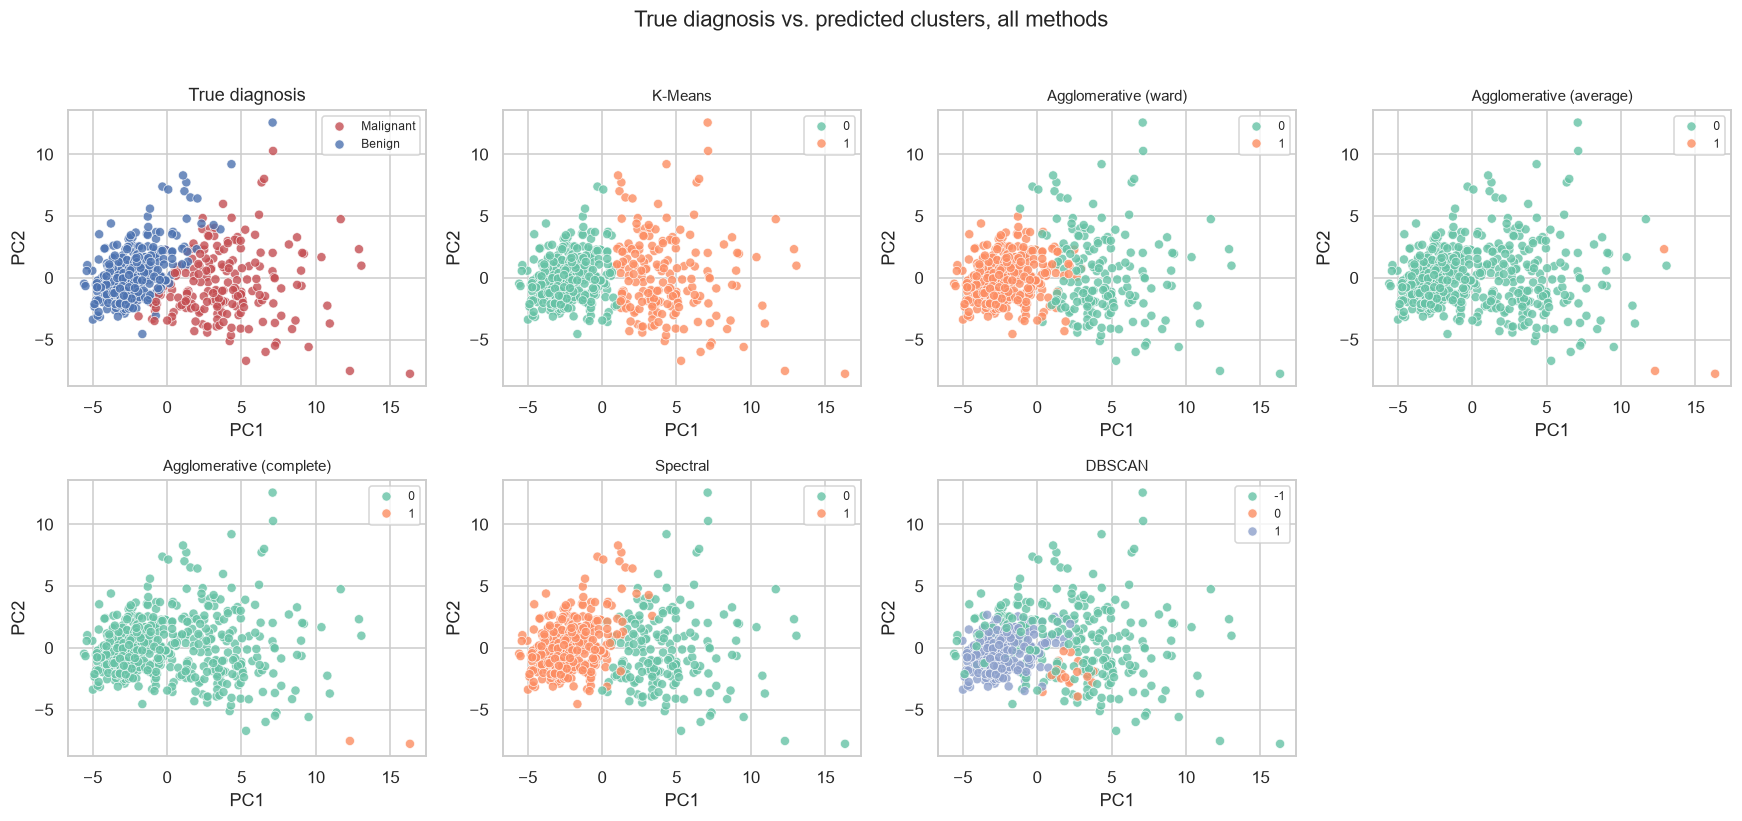


Top 3 clustering methods by ARI vs. true diagnosis:


,model,silhouette,ARI_vs_diagnosis
0,Spectral,0.336653,0.760801
1,K-Means,0.343382,0.653625
2,Agglomerative (ward),0.339385,0.575041


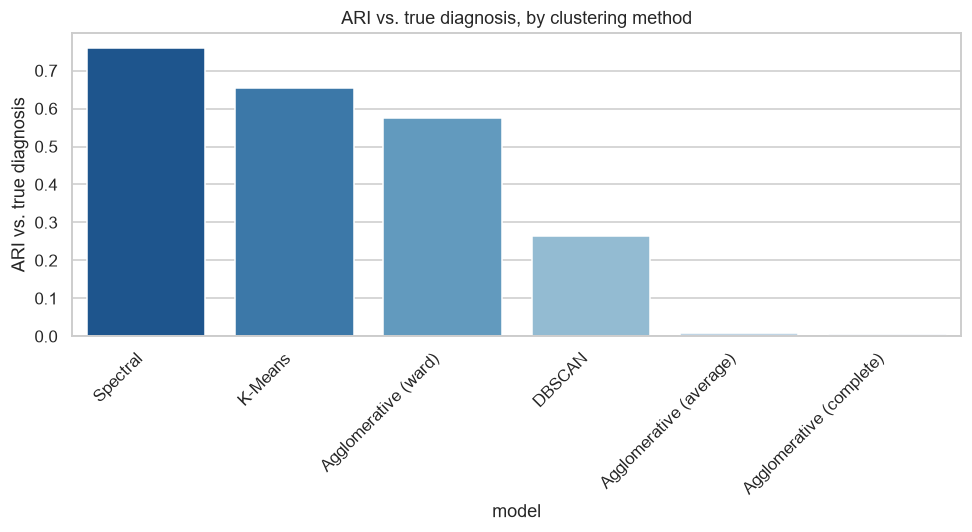

In [4]:
from unsupervised_models import get_baseline_clusterers
from evaluation import evaluate_clusterers
from plots import plot_all_clusters_vs_diagnosis, plot_ari_barplot

clusterers = get_baseline_clusterers(random_state=RANDOM_STATE)
clustering_eval = evaluate_clusterers(clusterers, X_scaled_full, df["label"].values)
clustering_eval.round(4).to_csv(os.path.join(RESULTS_DIR, "03_clustering_eval.csv"), index=False)

print("Clustering screening (all 569 samples, scaled, all 6 methods):")
display(clustering_eval.round(4))

# Re-fit each method to get its cluster labels for the comparison figure below --
# evaluate_clusterers only returns summary metrics, not the labels themselves.
cluster_labels_all = {name: algo.fit_predict(X_scaled_full) for name, algo in clusterers.items()}
plot_all_clusters_vs_diagnosis(
    X_pca_full, df["label"].values, cluster_labels_all,
    os.path.join(FIGURES_DIR, "03_all_clusters_vs_diagnosis.png")
)

# Condensed: top 3 by ARI vs. true diagnosis, the clearest single external
# validation metric for how well the natural clusters recover the known groups.
clustering_condensed = (
    clustering_eval.sort_values("ARI_vs_diagnosis", ascending=False)
    .loc[:, ["model", "silhouette", "ARI_vs_diagnosis"]]
    .head(3)
    .reset_index(drop=True)
)
clustering_condensed.to_csv(os.path.join(RESULTS_DIR, "03_screening_clustering_condensed.csv"), index=False)

print("\nTop 3 clustering methods by ARI vs. true diagnosis:")
display(clustering_condensed)

# Bar chart (for slides): ARI by method -- the metric that actually drives the
# choice below, unlike silhouette (see plot_ari_barplot's docstring for why).
plot_ari_barplot(clustering_eval, os.path.join(FIGURES_DIR, "03_ari_barplot.png"))

**Findings.** Spectral Clustering is the strongest unsupervised baseline by ARI. This
is not the same as having the highest silhouette: Agglomerative (average) and
Agglomerative (complete) actually reach a higher silhouette score, but their ARI is
close to zero. They likely collapse most points into one dominant cluster plus a
handful of outliers, a known failure mode of these two linkages, geometrically tight
but uninformative about the true diagnosis. This is why ARI, not silhouette, drives
the method choice here: Spectral Clustering was selected as the unsupervised "zoom"
method for this report, rather than any of the other 5 clustering methods screened.

## Discussion

Logistic Regression and Spectral Clustering stand out from this screening as the
strongest baselines, on recall and ARI respectively. Both are analyzed in depth in
the next notebooks, starting with a shared feature selection step in
`04_Feature_Selection.ipynb`.